# Machine learning SIS 2

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



df = pd.read_csv('bank-full.csv', sep=';')#потому что данные были все скомканы точкой запятой

df['y'] = (
    df['y']
    .str.strip()
    .str.lower()
    .map({'no': 0, 'yes': 1})
)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0


**education**
- tertiary - вышка

- secondary - 9-11/12 среднее

- primary - 1-4 or 1-6 началка 

**default** - просрачивал ли клиент кредит

**balance** - average balance in 1 year(euro)

**loan** - есть ли кредит

**housing** - есть ли кредит на жилье

**contact:** contact communication type (categorical: "unknown","telephone","cellular") 

**day:** last contact day of the month (numeric)

**month:** last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")

**duration** last contact duration, in seconds (numeric)

**campaign** - скок раз компания связывался с клиентом

**pdays** - скольк дней прошло после связи с клиентом, если -1 то с ним не связывались

**previous** - сколько раз связывались с клиентом перед текущейй рекламной компанией

**poutcome** - какой результат прошлой рекламной компании с клиентом, согласился или нет?

In [44]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [130]:
df.duplicated().sum()

np.int64(0)

In [91]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous,y
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323,0.116985
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441,0.321406
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000,1.000000


In [46]:
df.shape

(45211, 17)

In [47]:
cat_col = df.select_dtypes(include='object').columns
num_col = df.select_dtypes(exclude='object').columns.drop('y')

print(cat_col)
print(num_col)

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='object')
Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')


In [48]:
# df['marital'].hist()
#сделать функцию с group by которая будет строить графики и я буду смотреть какие фичи доминирует если человек в итоге берет эту рекламную компанию

In [49]:
df['y'].value_counts() # то есть у нас больльше отказывают чем принимаю рекламную компанию

y
0    39922
1     5289
Name: count, dtype: int64

In [50]:
print(df['y'].value_counts()[1]/(df['y'].value_counts()[0] + df['y'].value_counts()[1])) # скок всего ответов да

0.11698480458295547


In [51]:
print(df['y'].value_counts()[0]/(df['y'].value_counts()[0] + df['y'].value_counts()[1])) # скок отказов

# у нас присутствует имбаланс как минимум в ответах покупателей, большинство из них отказывают

0.8830151954170445


In [52]:
# df.groupby('y')['age'].hist(alpha=0.6, legend = True)
# plt.xlabel('Age')
# plt.ylabel('Quantity')

# #большинство типов которые отказывали были в промежутке от 30 до 41-42

In [53]:
# import seaborn as sns
# col_for_check  = ['age','job','marital','education','default','balance','housing','loan','contact','day','month','duration','campaign','pdays','previous','poutcome']


#     plt.figure(figsize=(15,5))
  
#     if df[item].dtype == 'object' or df[item].nunique() < 15: #nunique - если меньше то чаще всего категориальные колонки
#         ax = sns.countplot(data = df, x = item, hue='y')


#     else:
#         df.groupby('y')[item].hist(alpha=0.6, legend=True, bins=20)
#         plt.xlabel(item)  
#         plt.ylabel('Quantity')


In [54]:
pd.crosstab(df['job'], df['y'], normalize='index').round(2) # normalize='index' это чтобы были проценты

#большего всего брали студенты

y,0,1
job,,
admin.,0.88,0.12
blue-collar,0.93,0.07
entrepreneur,0.92,0.08
housemaid,0.91,0.09
management,0.86,0.14
retired,0.77,0.23
self-employed,0.88,0.12
services,0.91,0.09
student,0.71,0.29


In [55]:
cat_col_names = cat_col.tolist()

for item in cat_col_names:
    # print(item)
    print(pd.crosstab(df[item], df['y'], normalize='index').round(2), sep='\n')

y                 0     1
job                      
admin.         0.88  0.12
blue-collar    0.93  0.07
entrepreneur   0.92  0.08
housemaid      0.91  0.09
management     0.86  0.14
retired        0.77  0.23
self-employed  0.88  0.12
services       0.91  0.09
student        0.71  0.29
technician     0.89  0.11
unemployed     0.84  0.16
unknown        0.88  0.12
y            0     1
marital             
divorced  0.88  0.12
married   0.90  0.10
single    0.85  0.15
y             0     1
education            
primary    0.91  0.09
secondary  0.89  0.11
tertiary   0.85  0.15
unknown    0.86  0.14
y           0     1
default            
no       0.88  0.12
yes      0.94  0.06
y           0     1
housing            
no       0.83  0.17
yes      0.92  0.08
y        0     1
loan            
no    0.87  0.13
yes   0.93  0.07
y             0     1
contact              
cellular   0.85  0.15
telephone  0.87  0.13
unknown    0.96  0.04
y         0     1
month            
apr    0.80  0.20
aug    

Все что касается категориальных данных:

- job - берут депозит студенты 0.29
- marital - больше берут single - 0.15, a так же в разводе - 0.12,
- education - больше берут tertiary то есть люди с вышкой 0.15
- default - у кого его нет берут 0.12 
- housing - те кто платят кредит по квартире или дому берут очень мало 0.07, те кто без кредитов а точнее ипотек берут 0.17
- loan - те у кого нет кредитов берут больше 0.13
- contact - те кому писаи получается если cellular те берут больше депозит а точнее 0.15
- month - это когда связывались взяли больше всего депозит в декабре марте октябре и сентябре там значения в промежутке от 0.47 до 0.52
- poutcome - результат прошлой рекламной компании, те кто уже брал депозит берут еще раз 

последние 3 как будто не буду брать для определения




In [56]:
num_col

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')

In [57]:
df[num_col].describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Пока что сравниваю среднее и медиану:

- Age - разницы нет в mean and median практически
- Balance - big diff mean > median where mean = 1362 and median = 448
- Day - no diff almost
- Duration - diff mean > median where mean = 258, median = 180
- Campaign - not a big diff, this feature about how many times company contacted with a client
- Pday - big diff but because of -1 means that no contact before
- Previous  - also i don't think that i need to measure it 




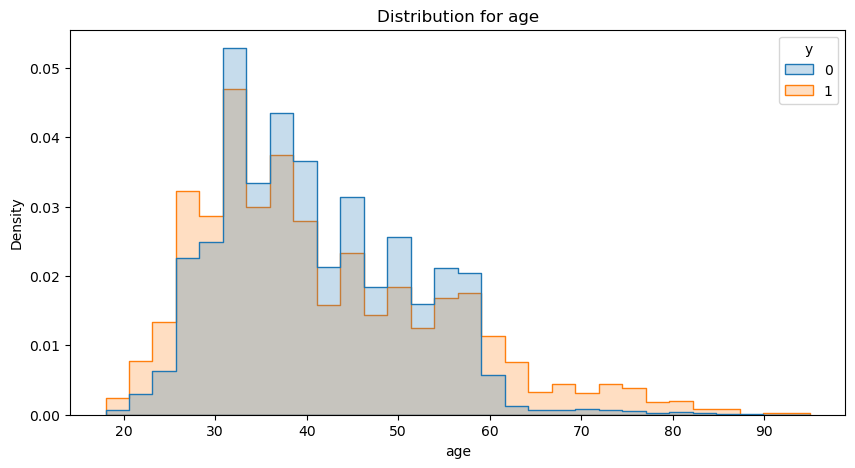

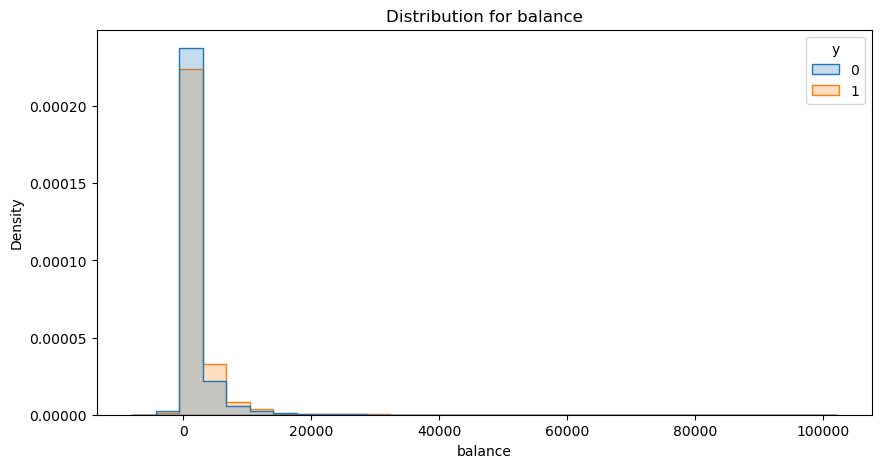

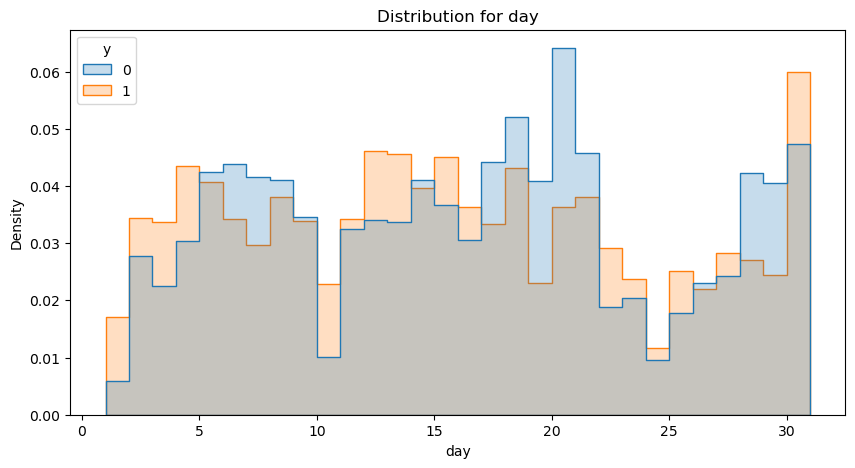

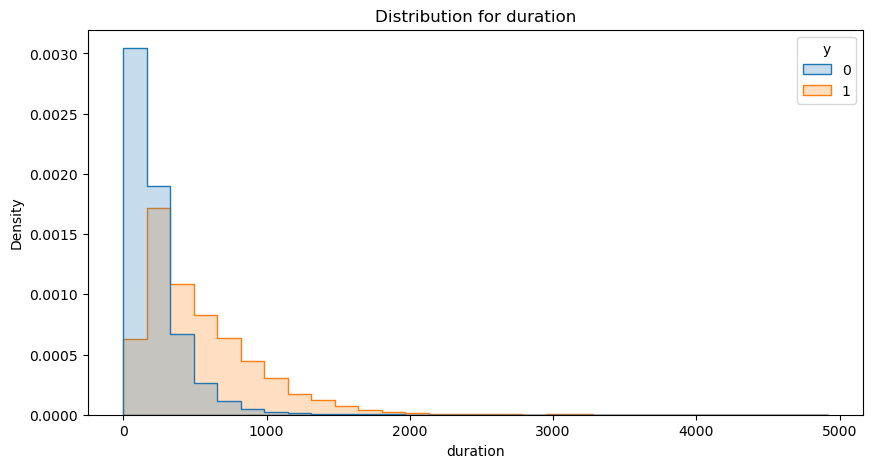

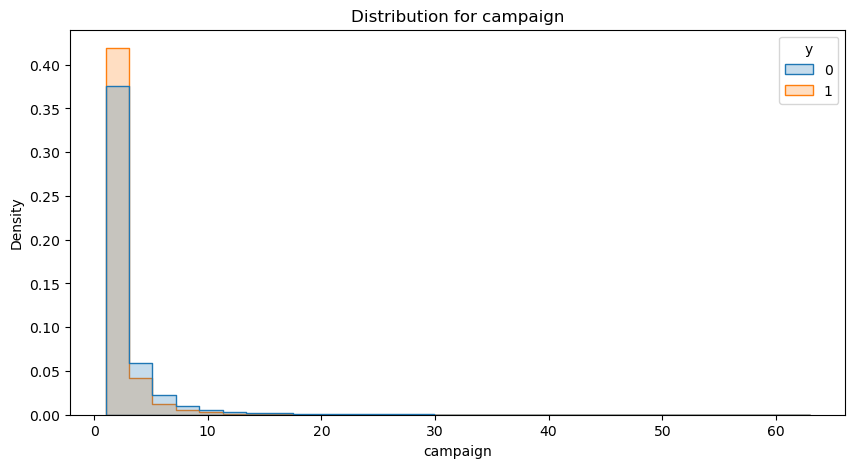

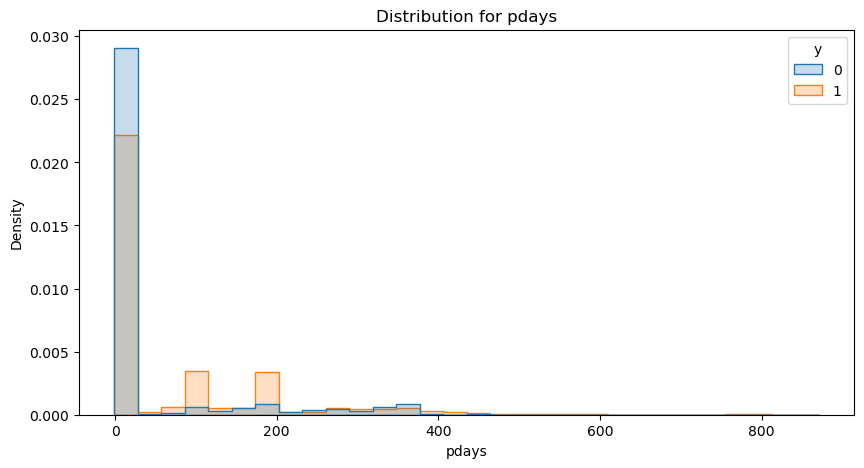

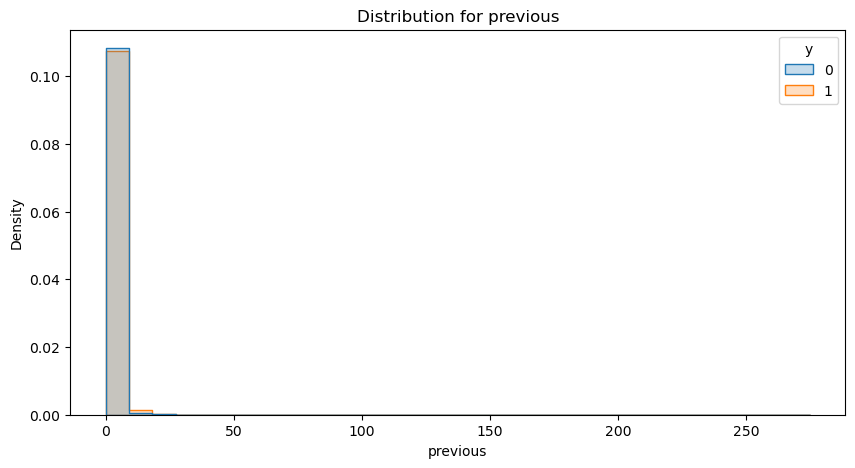

In [58]:
import seaborn as sns
num_col_names = num_col.tolist()


#hue это два графика накладываются друг на друга а может и больше графиков в зависимоти от вариции ответов в нашем target_value, который и есть y
#bins это количество столбиков
#density - показывает форму распределения, а не соотношение количества как было ранее
#common_norm = False для того чтобы распредеония правильно показались потому что у нас 0 доминирует и может форма класса 1 выглядить плоско
#elemnt=step оставляет видимые границы двух классов в нашем случае 0 и 1, то есть мы будем их различать на графике отчетливо

for items in df[num_col_names]:
    if items == 'y':
        continue
    else:
        plt.figure(figsize=(10,5))
        
        sns.histplot(data = df, x = items, hue='y', bins=30,stat='density',common_norm=False,element='step')
        plt.title(f'Distribution for {items}')
        plt.show()


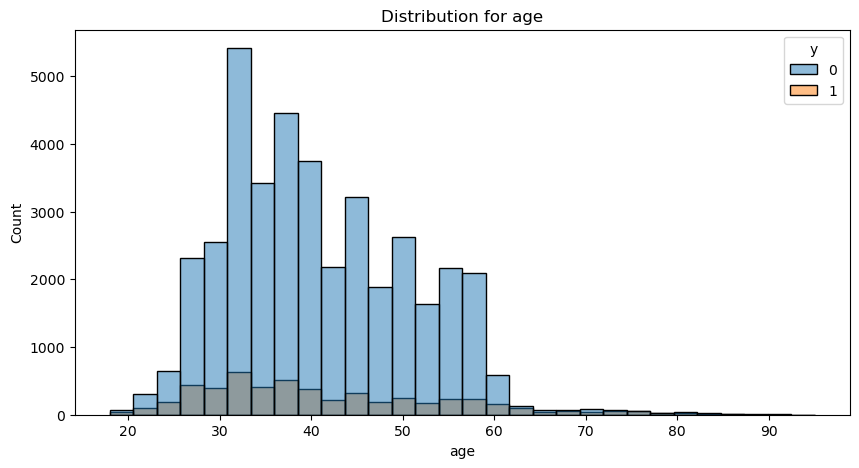

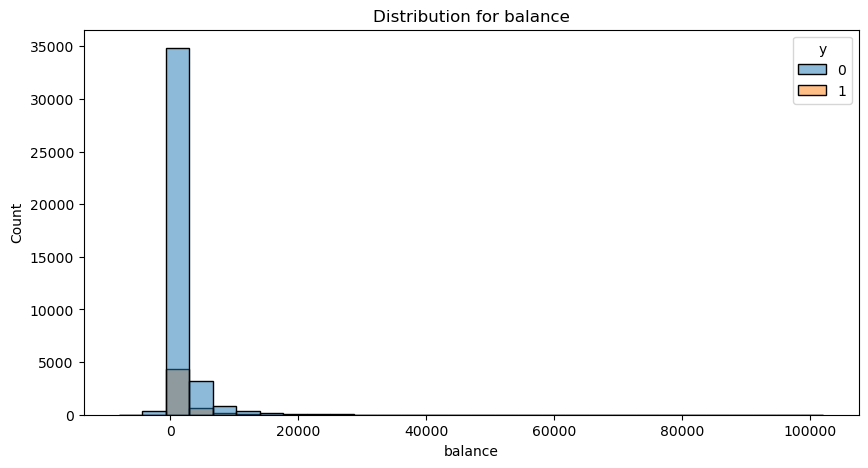

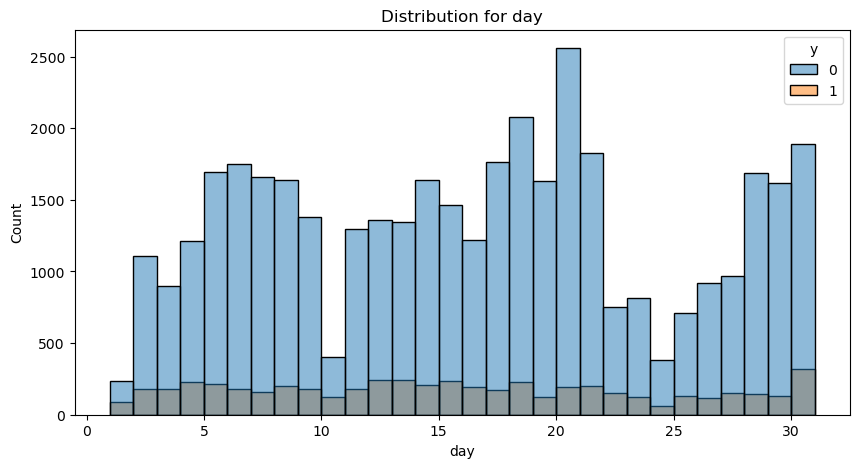

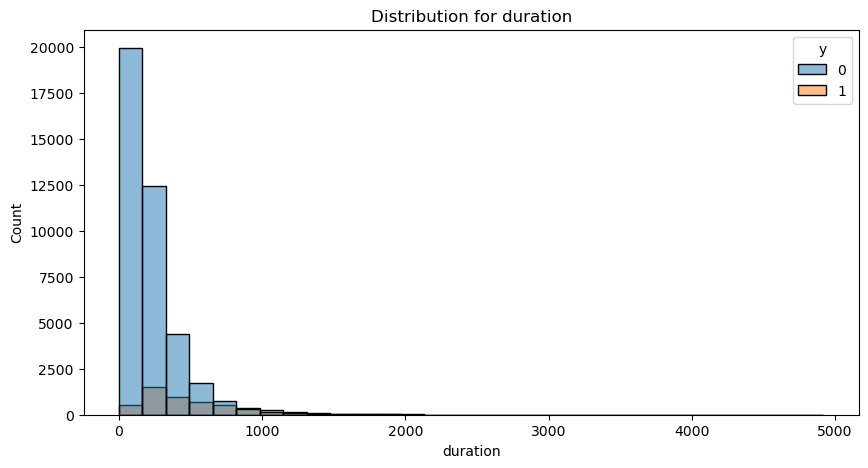

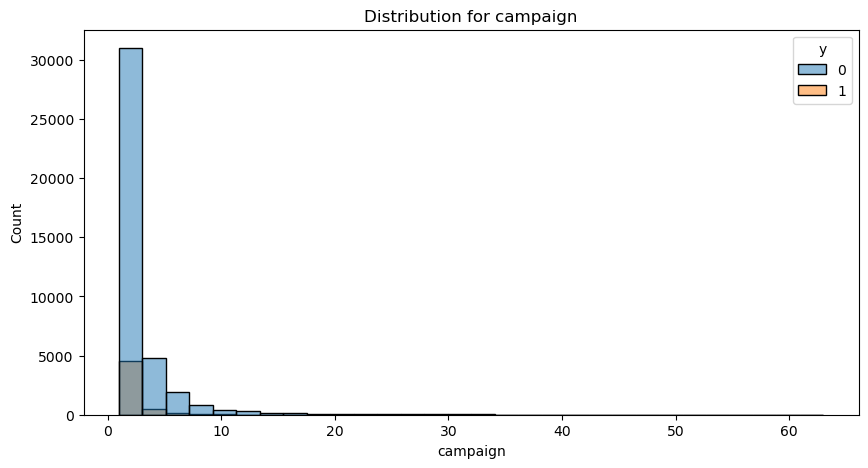

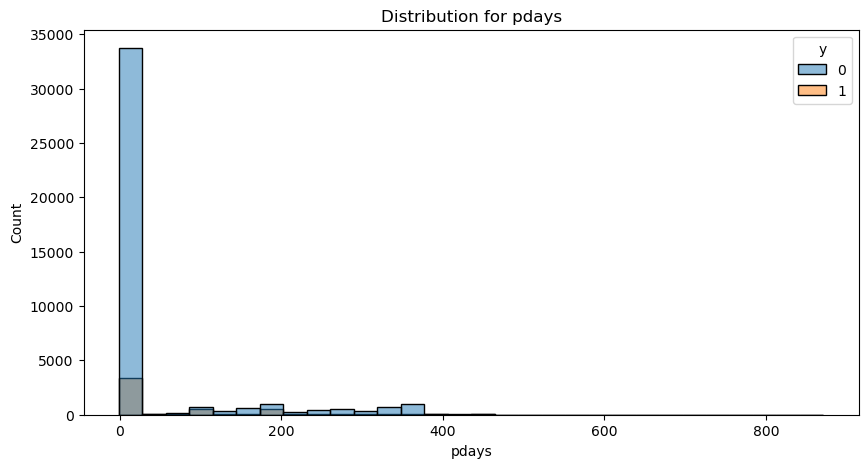

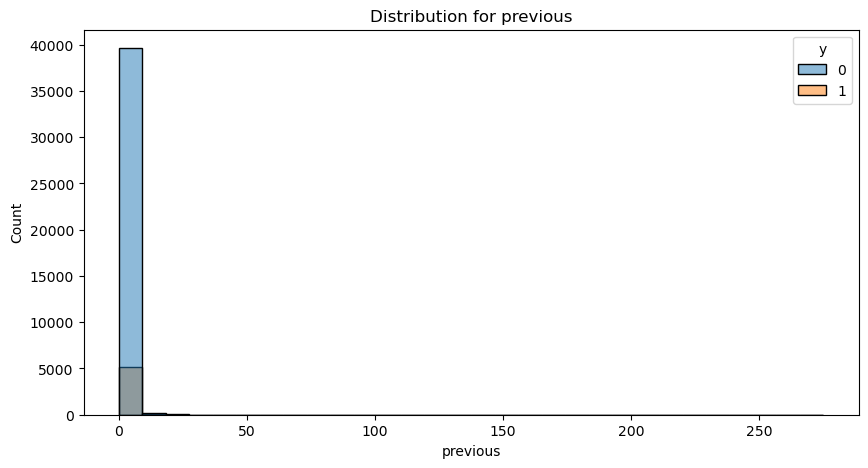

In [59]:
for items in df[num_col_names]:
    if items == 'y':
        continue
    else:
        plt.figure(figsize=(10,5))
        
        sns.histplot(data = df, x = items, hue='y', bins=30)
        plt.title(f'Distribution for {items}')
        plt.show()

In [60]:
df['age_group'] = pd.cut(df['age'], bins=[17,24,29,34,39,49,59,69,100])

In [61]:
df[['age','age_group']].head() # сделали короче диапазон

,age,age_group
0,58,"(49, 59]"
1,44,"(39, 49]"
2,33,"(29, 34]"
3,47,"(39, 49]"
4,33,"(29, 34]"


In [62]:
age_result =( df.groupby('age_group',observed=True)['y'].agg(['mean','count'])) #распрделели по группам и в каждой группе нас интересуе только y

age_result['mean'] = age_result['mean'] * 100
age_result

,mean,count
age_group,,
"(17, 24]",25.587145,809
"(24, 29]",16.151434,4464
"(29, 34]",10.800821,9740
"(34, 39]",10.312612,8349
"(39, 49]",9.120549,11655
"(49, 59]",9.334126,8410
"(59, 69]",29.674797,1230
"(69, 100]",42.418773,554


In [63]:
age_result = age_result.rename(
    columns={
        'mean':'subscription_rate',
        'count':'clients'
    }
)

age_result

,subscription_rate,clients
age_group,,
"(17, 24]",25.587145,809
"(24, 29]",16.151434,4464
"(29, 34]",10.800821,9740
"(34, 39]",10.312612,8349
"(39, 49]",9.120549,11655
"(49, 59]",9.334126,8410
"(59, 69]",29.674797,1230
"(69, 100]",42.418773,554


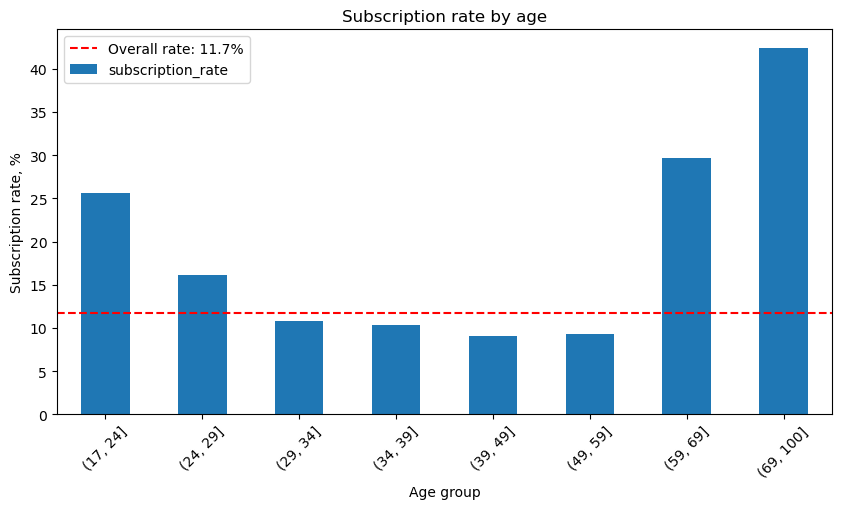

In [64]:
age_result['subscription_rate'].plot(kind='bar', figsize=(10,5))

plt.axhline(
    df['y'].mean() * 100,
    color='red',
    linestyle='--',
    label='Overall rate: 11.7%' #доля согласий по всей выборке
)

plt.ylabel('Subscription rate, %')
plt.xlabel('Age group')
plt.title('Subscription rate by age')
plt.xticks(rotation=45)
plt.legend()
plt.show()


#по графику видно что 3 самых больших группы это либо молодые ребята, либо люди старше 60 лет. то есть преимущественно молодые и престорелые берут депозит

In [65]:
df['balance'].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99])

count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
1%         -627.000000
5%         -172.000000
10%           0.000000
25%          72.000000
50%         448.000000
75%        1428.000000
90%        3574.000000
95%        5768.000000
99%       13164.900000
max      102127.000000
Name: balance, dtype: float64

In [84]:
df['balance_group'] = pd.cut(df['balance'], bins=[-np.inf, 0, 100, 500, 1000, 2000, 4000, 6000,np.inf])

df[['balance', 'balance_group']].head(10)

,balance,balance_group
0,2143,"(2000.0, 4000.0]"
1,29,"(0.0, 100.0]"
2,2,"(0.0, 100.0]"
3,1506,"(1000.0, 2000.0]"
4,1,"(0.0, 100.0]"
5,231,"(100.0, 500.0]"
6,447,"(100.0, 500.0]"
7,2,"(0.0, 100.0]"
8,121,"(100.0, 500.0]"
9,593,"(500.0, 1000.0]"


In [67]:
balance_result = df.groupby('balance_group', observed=True)['y'].agg(['mean','count'])

balance_result['mean'] = balance_result['mean'] * 100

balance_result

,mean,count
balance_group,,
"(-inf, 0.0]",6.895604,7280
"(0.0, 1.0]",8.717949,195
"(1.0, 100.0]",7.980000,5000
"(100.0, 500.0]",11.295800,11190
"(500.0, 1000.0]",12.422270,6915
"(1000.0, 2000.0]",13.686786,6130
"(2000.0, 4000.0]",17.184445,4603
"(4000.0, 6000.0]",16.703911,1790
"(6000.0, inf]",15.132827,2108


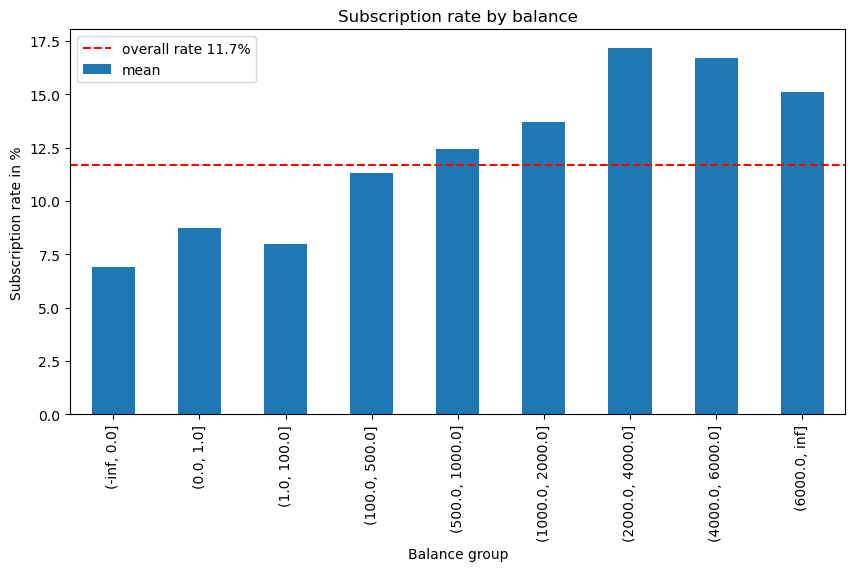

In [85]:
balance_result['mean'].plot(kind='bar', figsize=(10,5))


plt.axhline(df['y'].mean() * 100, color='red', linestyle='--', label='overall rate 11.7%')

plt.xlabel('Balance group')
plt.ylabel('Subscription rate in %')
plt.title('Subscription rate by balance')
plt.legend()
plt.show()


#видем рост процентов соглашения, чем больше денег на балике тем больше шанс, но этот рост работает вплоть до группы [2000,4000]


In [69]:
df['duration'].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99])

count    45211.000000
mean       258.163080
std        257.527812
min          0.000000
1%          11.000000
5%          35.000000
10%         58.000000
25%        103.000000
50%        180.000000
75%        319.000000
90%        548.000000
95%        751.000000
99%       1269.000000
max       4918.000000
Name: duration, dtype: float64

In [70]:
df['duration_group'] = pd.cut(df['duration'], bins=[-1,60,120,180,240,300,360,420,480,540,720, 900,np.inf])

df[['duration', 'duration_group']].head(10)

,duration,duration_group
0,261,"(240.0, 300.0]"
1,151,"(120.0, 180.0]"
2,76,"(60.0, 120.0]"
3,92,"(60.0, 120.0]"
4,198,"(180.0, 240.0]"
5,139,"(120.0, 180.0]"
6,217,"(180.0, 240.0]"
7,380,"(360.0, 420.0]"
8,50,"(-1.0, 60.0]"
9,55,"(-1.0, 60.0]"


In [71]:
duration_result = df.groupby('duration_group', observed=True)['y'].agg(['mean','count'])

duration_result['mean'] = duration_result['mean'] * 100

duration_result

,mean,count
duration_group,,
"(-1.0, 60.0]",0.188838,4766
"(60.0, 120.0]",2.177193,9278
"(120.0, 180.0]",5.779944,8616
"(180.0, 240.0]",9.661916,6034
"(240.0, 300.0]",12.703276,4243
"(300.0, 360.0]",14.109589,2920
"(360.0, 420.0]",17.880795,2114
"(420.0, 480.0]",20.391627,1481
"(480.0, 540.0]",25.336927,1113


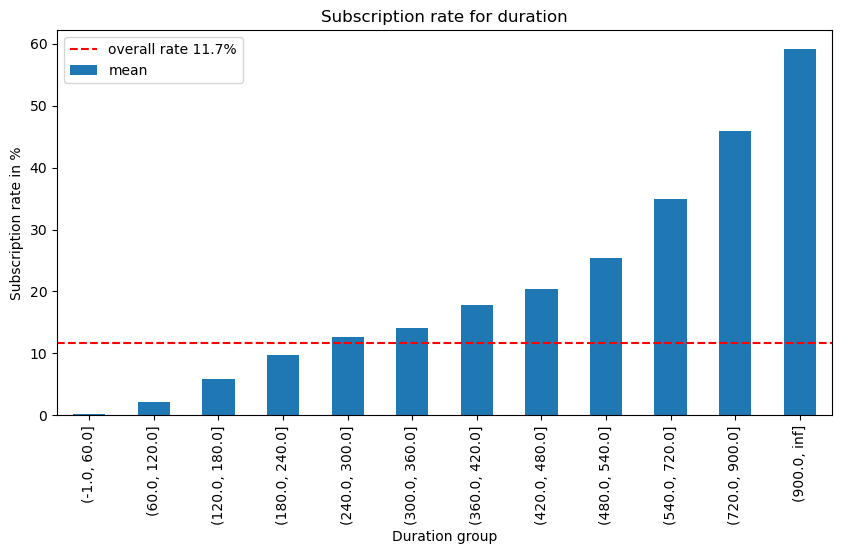

In [72]:
duration_result['mean'].plot(kind='bar', figsize=(10,5))

plt.axhline(df['y'].mean() * 100, color='red', linestyle='--', label='overall rate 11.7%')

plt.xlabel('Duration group')
plt.ylabel('Subscription rate in %')
plt.title('Subscription rate for duration')

plt.legend()
plt.show()

#как мы видим в зависимости от времени разговора происходтт такая тенденция если е етак можно назвать, чем больше общаются с клиентом тем больше возрасает шанс оформления депозита



In [73]:
# 'campaign', 'pdays', 'previous'

df['campaign'].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99])

count    45211.000000
mean         2.763841
std          3.098021
min          1.000000
1%           1.000000
5%           1.000000
10%          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
90%          5.000000
95%          8.000000
99%         16.000000
max         63.000000
Name: campaign, dtype: float64

In [74]:
df['campaign_groups'] = pd.cut(df['campaign'], bins=[0,1,2,3,5,np.inf])

campaign_result = df.groupby('campaign_groups', observed=True)['y'].agg(['mean','count', 'sum']) # количество оформлений - sum

campaign_result['mean'] = campaign_result['mean'] * 100

campaign_result


,mean,count,sum
campaign_groups,,,
"(0.0, 1.0]",14.597583,17544,2561
"(1.0, 2.0]",11.203519,12505,1401
"(2.0, 3.0]",11.193624,5521,618
"(3.0, 5.0]",8.626561,5286,456
"(5.0, inf]",5.809414,4355,253


**campaign** - скок раз компания связывался с клиентом

**pdays** - скольк дней прошло после связи с клиентом, если -1 то с ним не связывались

**previous** - сколько раз связывались с клиентом перед текущейй рекламной компанией

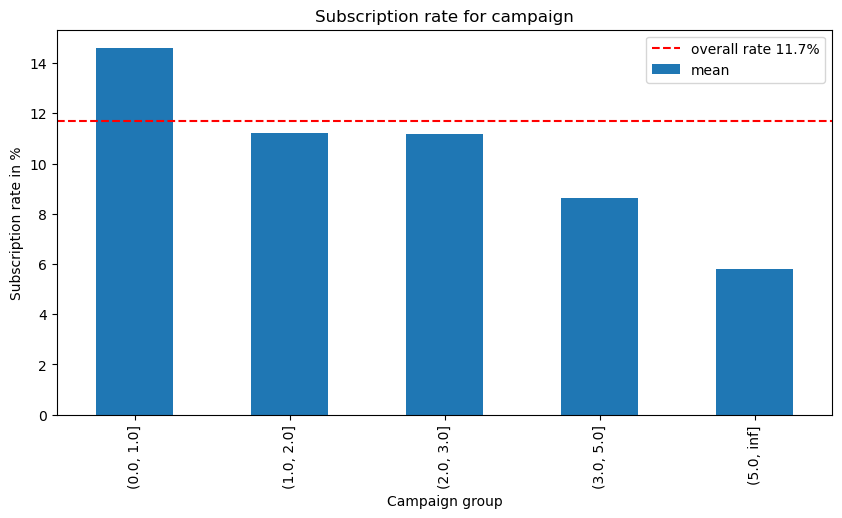

'Наибольшая доля оформлений наблюдается среди клиентов, с которыми связались один раз: 14,6%, или 2561 оформление из 17 544 клиентов. При двух и трёх контактах доля снижается примерно до 11,2%, а после трёх контактов продолжает уменьшаться. Таким образом, большое количество контактов в рамках текущей кампании связано с более низкой долей успешных оформлений.'

In [75]:
campaign_result['mean'].plot(kind='bar', figsize=(10,5))

plt.axhline(df['y'].mean() * 100, color='red', linestyle='--', label='overall rate 11.7%')

plt.xlabel('Campaign group')
plt.ylabel('Subscription rate in %')
plt.title('Subscription rate for campaign')

plt.legend()
plt.show()

'''Наибольшая доля оформлений наблюдается среди клиентов, с которыми связались один раз: 14,6%, или 2561 оформление из 17 544 клиентов. При двух и трёх контактах доля снижается примерно до 11,2%, а после трёх контактов продолжает уменьшаться. Таким образом, большое количество контактов в рамках текущей кампании связано с более низкой долей успешных оформлений.'''

In [76]:
df['pdays'].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99])

count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
1%          -1.000000
5%          -1.000000
10%         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
90%        185.000000
95%        317.000000
99%        370.000000
max        871.000000
Name: pdays, dtype: float64

In [77]:
df['previously_contacted'] = np.where(
    df['pdays'] == -1,
    'No',
    'Yes'
)

contact_result = (
    df.groupby('previously_contacted')['y'].agg(['mean', 'count', 'sum'])
)

contact_result['mean'] *= 100
contact_result

,mean,count,sum
previously_contacted,,,
No,9.157331,36954,3384
Yes,23.071333,8257,1905


Клиенты, с которыми банк связывался в рамках предыдущих маркетинговых кампаний, имеют значительно более высокую долю оформления депозита: 23,1% против 9,2% среди клиентов без предыдущего контакта.

In [78]:
contacted = df[df['pdays'] >= 0].copy()

contacted['pdays_group'] = pd.cut(
    contacted['pdays'],
    bins=[0, 30, 60, 90, 120, 180, 365, np.inf],
    include_lowest=True
)

pdays_result = (
    contacted.groupby('pdays_group', observed=True)['y']
             .agg(['mean', 'count', 'sum'])
)

pdays_result['mean'] *= 100
pdays_result

,mean,count,sum
pdays_group,,,
"(-0.001, 30.0]",14.893617,188,28
"(30.0, 60.0]",37.735849,106,40
"(60.0, 90.0]",43.160377,424,183
"(90.0, 120.0]",39.627434,1181,468
"(120.0, 180.0]",16.320246,1299,212
"(180.0, 365.0]",17.798913,4416,786
"(365.0, inf]",29.237947,643,188


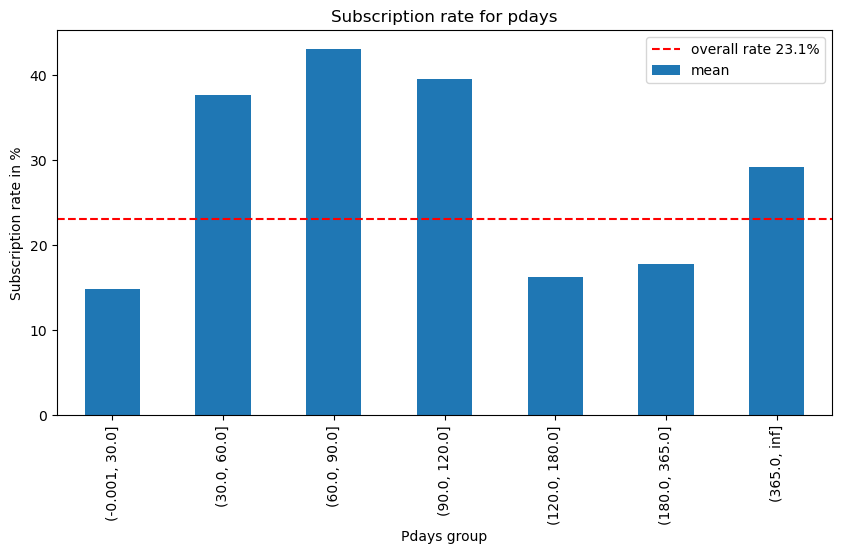

In [86]:
pdays_result['mean'].plot(kind='bar', figsize=(10,5))

plt.axhline(contacted['y'].mean() * 100, color='red', linestyle='--', label='overall rate 23.1%')

plt.xlabel('Pdays group')
plt.ylabel('Subscription rate in %')
plt.title('Subscription rate for pdays')

plt.legend()
plt.show()

Среди клиентов с историей предыдущего контакта наиболее высокая доля оформлений наблюдается в группах 60-90 дней - 43% и 90-120 дней — около 39%. Результат группы 90-120 дней выглядит более устойчивым, поскольку содержит 1181 клиентов, тогда как в группе 60-90 находится только 424 клиента. Эта зависимость не доказывает, что ожидание данного количества дней повышает вероятность оформления, поскольку результат также может зависеть от исхода предыдущей кампании и других факторов.

In [80]:
day_result = (
    df.groupby('day')['y']
      .agg(subscription_rate='mean', clients='size')
)

day_result['subscription_rate'] *= 100
day_result

,subscription_rate,clients
day,,
1,27.950311,322
2,14.075793,1293
3,16.496756,1079
4,15.916955,1445
5,11.256545,1910
6,9.368530,1932
7,8.640616,1817
8,10.912052,1842
9,11.467008,1561


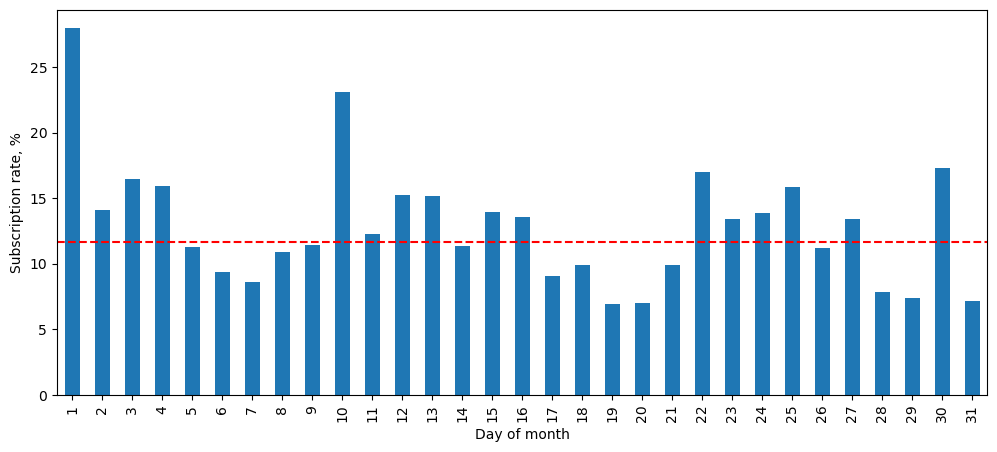

In [81]:
day_result['subscription_rate'].plot(
    kind='bar',
    figsize=(12, 5)
)

plt.axhline(
    df['y'].mean() * 100,
    color='red',
    linestyle='--'
)

plt.ylabel('Subscription rate, %')
plt.xlabel('Day of month')
plt.show()

In [82]:
#видно что берут в первый день больше всего депозит а потом почему то в 10 и в предпоследний день тоже берут норм

In [83]:
df['previous_group'] = pd.cut(
    df['previous'],
    bins=[-1, 0, 1, 2, 3, 5, 10, np.inf],
    labels=['0', '1', '2', '3', '4–5', '6–10', '11+']
)

previous_result = (
    df.groupby('previous_group', observed=True)['y']
      .agg(
          subscription_rate='mean',
          clients='size',
          subscriptions='sum'
      )
)

previous_result['subscription_rate'] *= 100
previous_result

,subscription_rate,clients,subscriptions
previous_group,,,
0,9.157331,36954,3384
1,21.031746,2772,583
2,21.652422,2106,456
3,25.744308,1142,294
4–5,24.893436,1173,292
6–10,29.350649,770,226
11+,18.367347,294,54


In [118]:
num_corr = [
    'age',
    'balance',
    'day',
    'duration',
    'campaign',
    'pdays',
    'previous',
    'y'
]
df[num_corr].corr(method='pearson')

,age,balance,day,duration,campaign,pdays,previous,y
age,1.000000,0.097783,-0.009120,-0.004648,0.004760,-0.023758,0.001288,0.025155
balance,0.097783,1.000000,0.004503,0.021560,-0.014578,0.003435,0.016674,0.052838
day,-0.009120,0.004503,1.000000,-0.030206,0.162490,-0.093044,-0.051710,-0.028348
duration,-0.004648,0.021560,-0.030206,1.000000,-0.084570,-0.001565,0.001203,0.394521
campaign,0.004760,-0.014578,0.162490,-0.084570,1.000000,-0.088628,-0.032855,-0.073172
pdays,-0.023758,0.003435,-0.093044,-0.001565,-0.088628,1.000000,0.454820,0.103621
previous,0.001288,0.016674,-0.051710,0.001203,-0.032855,0.454820,1.000000,0.093236
y,0.025155,0.052838,-0.028348,0.394521,-0.073172,0.103621,0.093236,1.000000


Also as we can see duration has a 0.39 corr with target value

# EDA summary


Dataset consist of 45211 rows and 16 columns and one target value. Our goal to predict whether person will open deposit or no. There is no missing values and no duplicate values, but we can see in dataset values like "unknown", ussualy in contact and poutcome columns.

After cheking target value it's looks really imbalanced, where 11.7% of clients made a deposit, and another part of them declined the offer. That's why i need to check f1-score, roc-auc, precision and recall, confusion matrix and etc.

Often deposit is opening by students and retired persons, where students - 29% and 23% of retired. They sure have a lot of percents but quantity of them not so a lot as another works.

Another interesting thing:
- Single clients open deposits more frequently (15%) than divorced (11.9%) or married (10.1%) clients.
- Clients with higher education have a higher deposit opening rate—around 15%.
- Clients without defaulted loans open deposits more often: 11.8% versus 6.4%.
- The deposit opening rate is 16.7% for clients without a housing loan, compared to 7.7% for those with one.
- The deposit opening rate is 12.7% for clients without a personal loan, compared to 6.7% for those with one.
- The deposit opening rate is higher when the contact method is known. It stands at 14.9% for mobile phones, whereas it is only 4.1% when the contact method is unknown.
- March, December, September, and October show a high rate of sign-ups, but the number of observations for these months is relatively low. Therefore, this result should be interpreted with caution.
- Following a successful previous campaign, approximately 64.7% of clients open a deposit. The `poutcome` variable shows one of the strongest associations with the target variable.

Numeric features:
- Balance and duration is right skewed, because there is a big difference between mean and median, where mean > median.
- A big group who open deposit is client who younger than 25 and clients who older than 60
- Also a good observation is that, if balance grows then chance of opening deposit is also grows, but this observation is working untill 2000-4000 euro group
- No simple or consistent relationship was found for "day".
- The longer the conversation lasts, the higher the observed conversion rate. However, the duration becomes known only after the call and could lead to data leakage if the model is required to make a prediction prior to contact with the client.Also as we can see duration has a 0.39 corr with target value
- As the number of contacts in the current campaign increases, the rate of account openings declines: it stands at 14.6% after a single contact, 8.6% after 4–5 contacts, and 5.8% after 6 or more.
- Customers contacted in previous campaigns open deposits more frequently: 23.1% compared to 9.2% for those with no prior contact.
- Among customers with a contact history, an elevated rate of account openings is observed after approximately 60–120 days. This does not prove that this interval is the optimal time for a call.
- With 6–10 previous contacts, the account opening rate is 29.4%, but this group comprises only 770 customers. It cannot be asserted that this specific number of contacts increases the likelihood of opening an account.

I think i will measure model performance with duration and without duration, if there is no difference we will see.



# Preprocess data

In [119]:
original_columns = [
    'age',
    'job',
    'marital',
    'education',
    'default',
    'balance',
    'housing',
    'loan',
    'contact',
    'day',
    'month',
    # 'duration',
    'campaign',
    'pdays',
    'previous',
    'poutcome',
    'y'
]

df_v1 = df[original_columns].copy()



im not using right now duration because it can cause data leakage. As we've seen before duration has corelation with target value 0.39 and now as i build baseline model, duration feature is not using right now

In [120]:
df_v1.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,0


In [121]:
X = df_v1.drop('y', axis=1)
y = df_v1['y'].copy()

print(X.shape)
print(y.shape)

(45211, 15)
(45211,)


In [122]:
from sklearn.model_selection import train_test_split

#stratify=y значит что не будет имбаланса то есть количество в train and test нашей target value будет одинаково
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, stratify=y, random_state=42)

In [123]:
num_col_v1 = X.select_dtypes(exclude='object').columns
cat_col_v1 = X.select_dtypes(include='object').columns

df_v1[num_col_v1].head()

,age,balance,day,campaign,pdays,previous
0,58,2143,5,1,-1,0
1,44,29,5,1,-1,0
2,33,2,5,1,-1,0
3,47,1506,5,1,-1,0
4,33,1,5,1,-1,0


In [124]:
df_v1[cat_col_v1].head()

,job,marital,education,default,housing,loan,contact,month,poutcome
0,management,married,tertiary,no,yes,no,unknown,may,unknown
1,technician,single,secondary,no,yes,no,unknown,may,unknown
2,entrepreneur,married,secondary,no,yes,yes,unknown,may,unknown
3,blue-collar,married,unknown,no,yes,no,unknown,may,unknown
4,unknown,single,unknown,no,no,no,unknown,may,unknown


Now i splitted train and test data, and also categorical columns and numerical. So the next step is to make scaling for numerical columns and then for categorical.

In [126]:
df_v1[num_col_v1].describe()
#age+, balance-, day+, duration-, campaign+, another is not interesting

,age,balance,day,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,63.000000,871.000000,275.000000


In [127]:
#iqr = q3 - q1
#lower_bound = q1 - 1.5*iqr
#upper_bound = q3 + 1.5*iqr

outlier_count = []

for items in df_v1[num_col_v1]:

    q1 = df_v1[items].quantile(0.25)
    q3 = df_v1[items].quantile(0.75)

    iqr = q3 - q1
    lower_bound = q1 - 1.5*iqr
    upper_bound = q3 + 1.5*iqr

    outlier_mask = (df_v1[items] < lower_bound) | (df_v1[items] > upper_bound)
    outlier_count.append(outlier_mask.sum())

outlier_count_table = pd.DataFrame({
    'Features': num_col_v1,
    'Outlier count': outlier_count
})

outlier_count_table

,Features,Outlier count
0,age,487
1,balance,4729
2,day,0
3,campaign,3064
4,pdays,8257
5,previous,8257


As we can see there is some outliers in numercial features, so i wanna to try robustscaler for this sis2, but of course i will check standard scaler later.There is one more thing left and after i can start creating columntransformer. I just need to think which encoder i need to use.

In [128]:
df_v1[cat_col_names].head()

,job,marital,education,default,housing,loan,contact,month,poutcome
0,management,married,tertiary,no,yes,no,unknown,may,unknown
1,technician,single,secondary,no,yes,no,unknown,may,unknown
2,entrepreneur,married,secondary,no,yes,yes,unknown,may,unknown
3,blue-collar,married,unknown,no,yes,no,unknown,may,unknown
4,unknown,single,unknown,no,no,no,unknown,may,unknown


- 2 - job : type of job (categorical: "admin.","unknown","unemployed","management","housemaid","entrepreneur","student","blue-collar","self-employed","retired","technician","services") 
- 3 - marital : marital status (categorical: "married","divorced","single"; note: "divorced" means divorced or widowed)
- 4 - education (categorical: "unknown","secondary","primary","tertiary")
- 5 - default: has credit in default? (binary: "yes","no")
- 7 - housing: has housing loan? (binary: "yes","no")
- 8 - loan: has personal loan? (binary: "yes","no")
- 9 - contact: contact communication type (categorical: "unknown","telephone","cellular") 
- 11 - month: last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")
- 6 - poutcome: outcome of the previous marketing campaign (categorical: "unknown","other","failure","success")


I will definetely use onehotecoder, maybe later i will use Ordinal Encoder for education, but not now.


In [129]:
#one-hot
#robustscaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import OneHotEncoder

col_trans = ColumnTransformer([
    ('num_col', RobustScaler(), num_col_v1),
    ('cat_col', OneHotEncoder(), cat_col_v1)
])



